# Employee Attrition Prediction with Python

**Problem Statement:**  
Employee attrition means employees leaving the organization. Organizations lose a lot of time and money when trained employees quit. The goal of this project is to **predict whether an employee will leave the company or not** using Machine Learning.

**Dataset:** IBM HR Analytics Employee Attrition Dataset  
- 1470 employee records  
- 35 features (Age, Department, Salary, JobSatisfaction, etc.)  
- Target: **Attrition** (Yes = left the company, No = stayed)

**Approach:**
1. Exploratory Data Analysis (EDA)
2. Feature Engineering
3. Handling Class Imbalance (SMOTE)
4. Random Forest Classification
5. Feature Importance Analysis

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import plotly.express as px
import plotly.graph_objects as go

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

print('All libraries imported successfully!')

All libraries imported successfully!


## Step 2: Load the Dataset

In [5]:
df = pd.read_csv('Employee Attrition.csv')

In [6]:
df.shape

(1470, 35)

## Step 3: Exploratory Data Analysis (EDA)

In [11]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [12]:
print('Attrition Count:')
print(df['Attrition'].value_counts())

Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [13]:
print('Attrition Percentage:')
print(df['Attrition'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

Attrition Percentage:
Attrition
No     83.88%
Yes    16.12%
Name: proportion, dtype: object


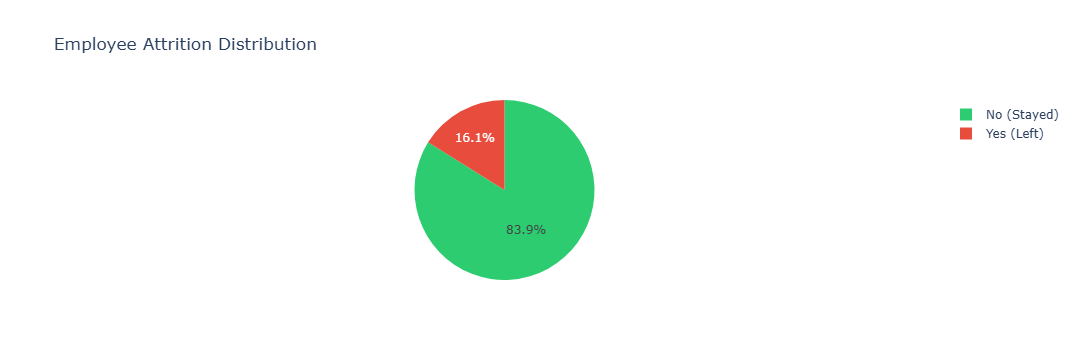

In [14]:
# Attrition distribution - Pie Chart
fig = px.pie(
    values=df['Attrition'].value_counts().values,
    names=['No (Stayed)', 'Yes (Left)'],
    title='Employee Attrition Distribution',
    color_discrete_sequence=['#2ecc71', '#e74c3c']
)
fig.show()

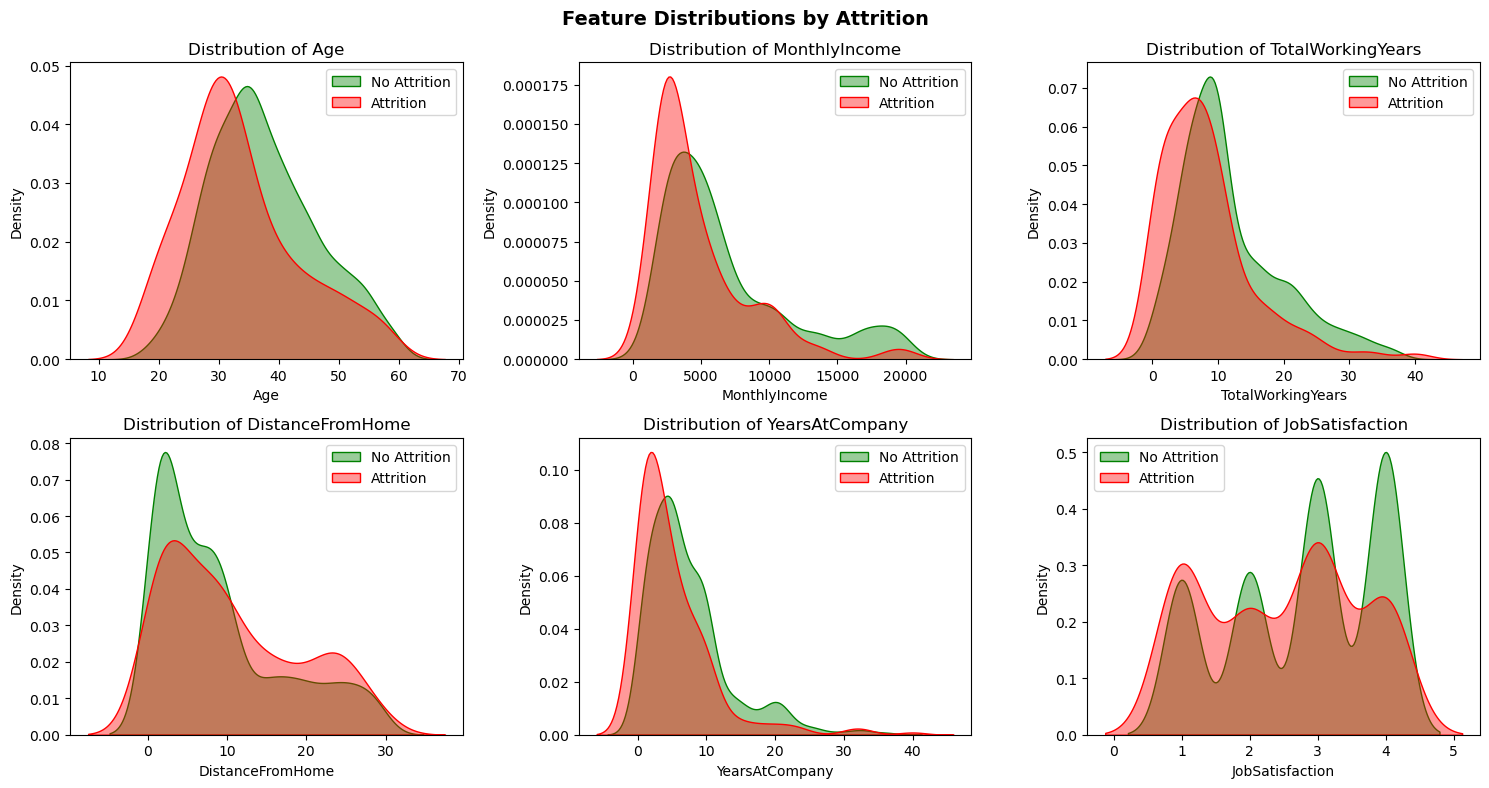

In [16]:
# KDE Plot - Distribution of key numerical features by Attrition
# KDE (Kernel Density Estimation) shows how values are distributed
# Green = Stayed, Red = Left

numerical_features = ['Age', 'MonthlyIncome', 'TotalWorkingYears',
                       'DistanceFromHome', 'YearsAtCompany', 'JobSatisfaction']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.kdeplot(
        data=df[df['Attrition'] == 'No'][feature],
        ax=axes[i], label='No Attrition', color='green', fill=True, alpha=0.4
    )
    sns.kdeplot(
        data=df[df['Attrition'] == 'Yes'][feature],
        ax=axes[i], label='Attrition', color='red', fill=True, alpha=0.4
    )
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].legend()

plt.suptitle('Feature Distributions by Attrition', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
df.Department.value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

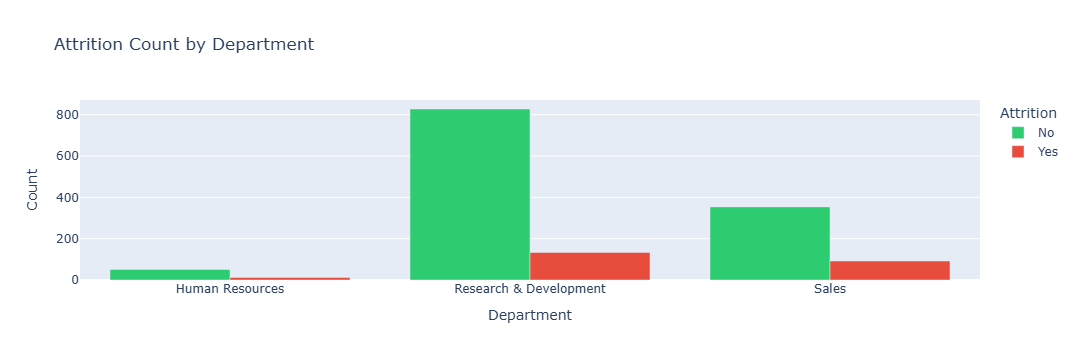

In [18]:
# Attrition by Department
dept_attrition = df.groupby(['Department', 'Attrition']).size().reset_index(name='Count')

fig = px.bar(
    dept_attrition,
    x='Department', y='Count', color='Attrition',
    barmode='group',
    title='Attrition Count by Department',
    color_discrete_map={'Yes': '#e74c3c', 'No': '#2ecc71'}
)
fig.show()

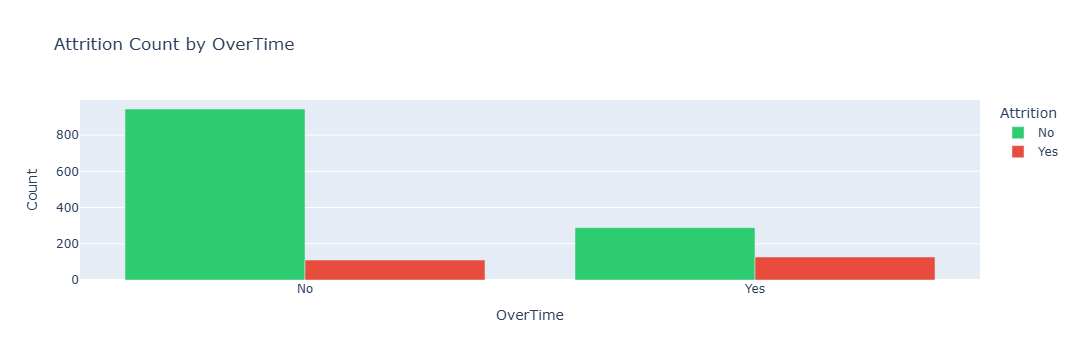

In [21]:
# Attrition by OverTime
ot_attrition = df.groupby(['OverTime', 'Attrition']).size().reset_index(name='Count')

fig = px.bar(
    ot_attrition,
    x='OverTime', y='Count', color='Attrition',
    barmode='group',
    title='Attrition Count by OverTime',
    color_discrete_map={'Yes': '#e74c3c', 'No': '#2ecc71'}
)
fig.show()

### Correlation Matrix
Correlation matrix batata hai ki kaunse features ek doosre se related hain.  
Value +1 = strong positive correlation, -1 = strong negative correlation, 0 = no relation

The correlation heatmap shows relationships between numerical features. Some features like YearsAtCompany, YearsInCurrentRole, and YearsWithCurrManager are highly correlated. However, since we are using a Random Forest model, multicollinearity is not a major concern.

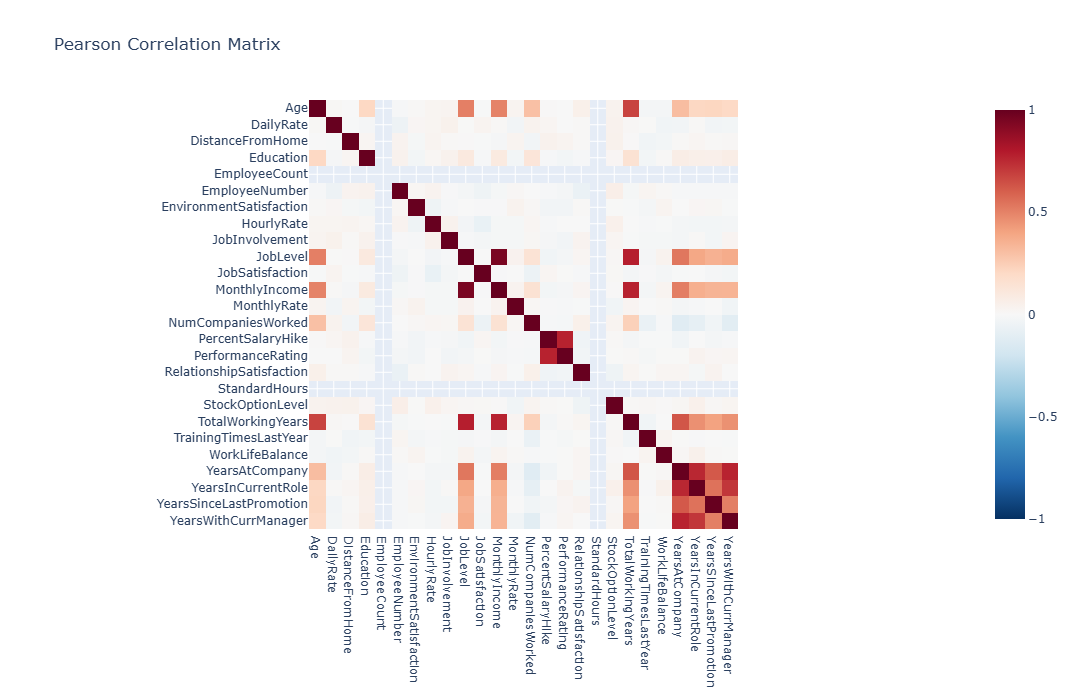

In [22]:
# Select only numerical columns for correlation
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[num_cols].corr()

# Interactive Plotly Heatmap
fig = px.imshow(
    corr_matrix,
    title='Pearson Correlation Matrix',
    color_continuous_scale='RdBu_r',
    zmin=-1, zmax=1,
    width=800, height=700
)
fig.show()

## Step 4: Feature Engineering

Machine Learning models sirf **numbers** samajh sakte hain — text nahi.  
Isliye hum:
1. Categorical columns ko `pd.get_dummies()` se numerical mein convert karenge
2. Target variable (Attrition) ko Yes=1, No=0 mein encode karenge

In [24]:
# Separate categorical and numerical columns
categorical = [col for col in df.columns if df[col].dtype == 'object']
numerical   = [col for col in df.columns if df[col].dtype != 'object']

print('Categorical Columns:', categorical)
print()
print('Numerical Columns:', numerical)

Categorical Columns: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

Numerical Columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [25]:
# Encode categorical columns using One-Hot Encoding (get_dummies)
# Drop 'Attrition' from categorical (it's our target, handle separately)
attrition_cat = df[categorical].drop(['Attrition'], axis=1)
attrition_cat = pd.get_dummies(attrition_cat)

print('Categorical columns after encoding:')
print('Shape:', attrition_cat.shape)
attrition_cat.head(3)

Categorical columns after encoding:
Shape: (1470, 29)


,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Human Resources,Department_Research & Development,Department_Sales,EducationField_Human Resources,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,...,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,Over18_Y,OverTime_No,OverTime_Yes
0,False,False,True,False,False,True,False,True,False,False,...,False,False,True,False,False,False,True,True,False,True
1,False,True,False,False,True,False,False,True,False,False,...,False,True,False,False,False,True,False,True,True,False
2,False,False,True,False,True,False,False,False,False,False,...,False,False,False,False,False,False,True,True,False,True


In [26]:
# Numerical columns
attrition_num = df[numerical]

# Remove useless constant columns (EmployeeCount=1 always, StandardHours=80 always, Over18=Y always)
attrition_num = attrition_num.drop(['EmployeeCount', 'StandardHours', 'EmployeeNumber'], axis=1)

print('Numerical columns shape:', attrition_num.shape)
attrition_num.head(3)

Numerical columns shape: (1470, 23)


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1102,1,2,2,94,3,2,4,5993,...,3,1,0,8,0,1,6,4,0,5
1,49,279,8,1,3,61,2,2,2,5130,...,4,4,1,10,3,3,10,7,1,7
2,37,1373,2,2,4,92,2,1,3,2090,...,3,2,0,7,3,3,0,0,0,0


In [27]:
# Combine numerical + encoded categorical into final feature matrix
attrition_final = pd.concat([attrition_num, attrition_cat], axis=1)

print('Final Feature Matrix Shape:', attrition_final.shape)
attrition_final.head(3)

Final Feature Matrix Shape: (1470, 52)


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,Over18_Y,OverTime_No,OverTime_Yes
0,41,1102,1,2,2,94,3,2,4,5993,...,False,False,True,False,False,False,True,True,False,True
1,49,279,8,1,3,61,2,2,2,5130,...,False,True,False,False,False,True,False,True,True,False
2,37,1373,2,2,4,92,2,1,3,2090,...,False,False,False,False,False,False,True,True,False,True


In [96]:
# Encode Target Variable: Yes → 1, No → 0
target_map = {'Yes': 1, 'No': 0}
target = df['Attrition'].apply(lambda x: target_map[x])

print('Target variable (first 10 values):')
target.values[:10]

Target variable (first 10 values):


array([1, 0, 1, 0, 0, 0, 0, 0, 0, 0])

In [95]:
print('Target distribution:')
target.value_counts()

Target distribution:


Attrition
0    1233
1     237
Name: count, dtype: int64

## Step 5: Handle Class Imbalance using SMOTE

**Problem:** Dataset mein 1233 'No' aur sirf 237 'Yes' hain — yeh **class imbalance** hai.  
Agar seedha train karein toh model 'No' predict karne mein expert ho jayega, 'Yes' miss karega.

**SMOTE (Synthetic Minority Oversampling Technique):**  
Minority class (Yes) ke liye synthetic/fake samples generate karta hai taaki dono classes equal ho jayein.

In [33]:
(1233+237)*80/100

1176.0

In [29]:
# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    attrition_final, target, test_size=0.2, random_state=42, stratify=target
)

print('Before SMOTE:')
print(f'  Training samples : {len(X_train)}')
print(f'  Testing samples  : {len(X_test)}')
print(f'  Train class dist : {dict(y_train.value_counts())}')

Before SMOTE:
  Training samples : 1176
  Testing samples  : 294
  Train class dist : {0: np.int64(986), 1: np.int64(190)}


In [52]:
len(X_train.columns)

52

In [99]:
# Apply SMOTE on training data only (NEVER on test data)
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('After SMOTE:')
print(f'  Training samples : {X_train_sm.shape[0]}')
print(f'  Train class dist : {dict(pd.Series(y_train_sm).value_counts())}')
print('\nNow both classes are balanced!')

After SMOTE:
  Training samples : 1972
  Train class dist : {0: np.int64(986), 1: np.int64(986)}

Now both classes are balanced!


## Step 6: Train Random Forest Classifier

**Random Forest** ek ensemble model hai jo kai saare Decision Trees banata hai aur unka majority vote leta hai.  
Yeh model:
- Overfitting se bachta hai
- Feature importance bhi de sakta hai
- Tabular data pe bahut acha perform karta hai

In [35]:
# Initialize and train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,   # 100 decision trees
    max_depth=10,       # max depth of each tree
    random_state=42,
    n_jobs=-1           # use all CPU cores
)

print('Training Random Forest...')
rf_model.fit(X_train_sm, y_train_sm)
print('Training complete!')

Training Random Forest...
Training complete!


## Step 7: Evaluate Model Performance

In [36]:
# Predictions on test data
y_pred = rf_model.predict(X_test)

# Metrics
acc = accuracy_score(y_test, y_pred)

print(f'Accuracy Score: {acc:.4f}')
# print('=' * 60)
# print(classification_report(y_test, y_pred, target_names=['No Attrition (0)', 'Attrition (1)']))

Accuracy Score: 0.8639


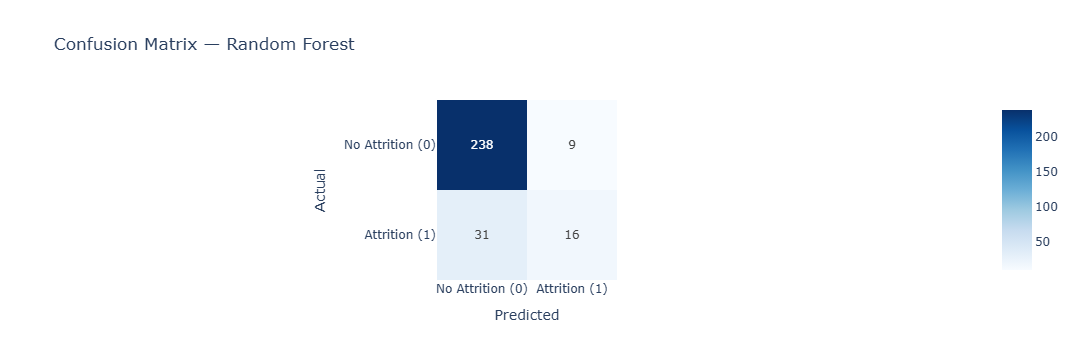

Confusion Matrix Explanation:
  True Negative  (Predicted No,  Actual No)  : 238
  False Positive (Predicted Yes, Actual No)  : 9
  False Negative (Predicted No,  Actual Yes) : 31
  True Positive  (Predicted Yes, Actual Yes) : 16


In [40]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig = px.imshow(
    cm,
    labels=dict(x='Predicted', y='Actual'),
    x=['No Attrition (0)', 'Attrition (1)'],
    y=['No Attrition (0)', 'Attrition (1)'],
    text_auto=True,
    color_continuous_scale='Blues',
    title='Confusion Matrix — Random Forest'
)
fig.show()

print('Confusion Matrix Explanation:')
print(f'  True Negative  (Predicted No,  Actual No)  : {cm[0][0]}')
print(f'  False Positive (Predicted Yes, Actual No)  : {cm[0][1]}')
print(f'  False Negative (Predicted No,  Actual Yes) : {cm[1][0]}')
print(f'  True Positive  (Predicted Yes, Actual Yes) : {cm[1][1]}')

## Step 8: Feature Importance Analysis

Random Forest ek powerful feature batata hai — **Feature Importance**.  
Yeh batata hai ki kaunse features ne model ke prediction mein sabse zyada role play kiya.

In [87]:
# Get feature importances from the trained model
feature_importances = pd.DataFrame({
    'Feature': attrition_final.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

# # Top 20 most important features
# top20 = feature_importances.head(20)

# print('Top 20 Most Important Features:')
# print(top20.to_string(index=False))
print(feature_importances.shape)

(52, 2)


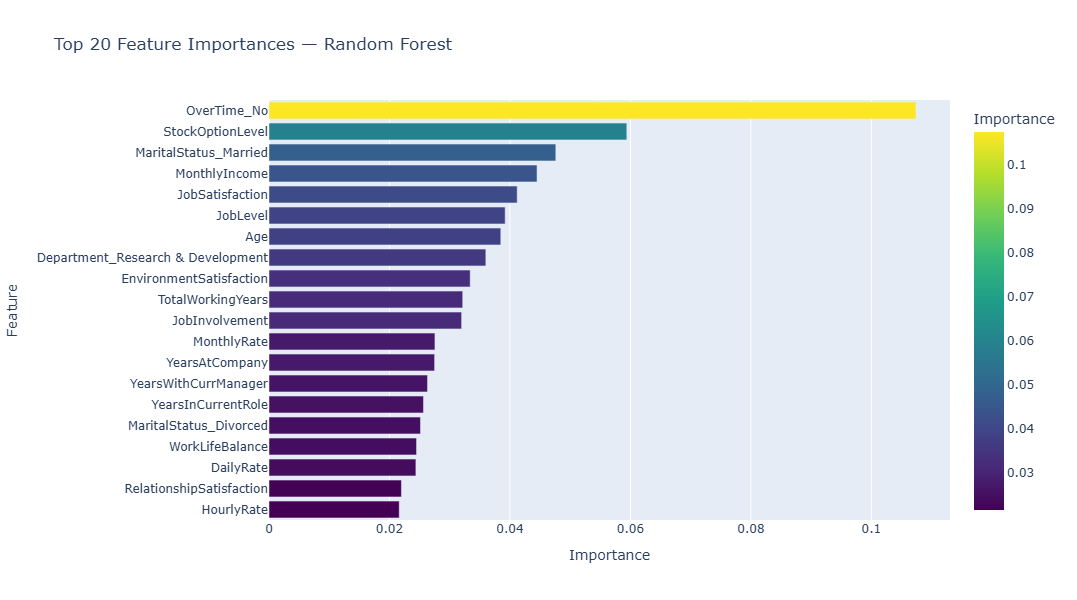

In [39]:
# Visualize Feature Importance with Plotly
fig = px.bar(
    top20.sort_values('Importance', ascending=True),
    x='Importance',
    y='Feature',
    orientation='h',
    title='Top 20 Feature Importances — Random Forest',
    color='Importance',
    color_continuous_scale='Viridis'
)
fig.update_layout(height=600)
fig.show()

## Step 9: Test Prediction on Custom Employee Data

In [51]:
df.shape[1]

35

In [49]:
len(new_employee)

24

In [74]:
new_employee = {
    'Age': 35,
    'BusinessTravel': 'Travel_Rarely',
    'DailyRate': 800,
    'Department': 'Sales',
    'DistanceFromHome': 30,
    'Education': 3,
    'EducationField': 'Life Sciences',
    'EnvironmentSatisfaction': 4,
    'Gender': 'Male',
    'JobInvolvement': 3,
    'JobLevel': 2,
    'JobRole': 'Sales Executive',
    'JobSatisfaction': 3,
    'MaritalStatus': 'Married',
    'MonthlyIncome': 1000,
    'NumCompaniesWorked': 2,
    'OverTime': 'Yes',
    'PercentSalaryHike': 4,
    'TotalWorkingYears': 10,
    'WorkLifeBalance': 3,
    'YearsAtCompany': 5,
    'YearsInCurrentRole': 3,
    'YearsSinceLastPromotion': 1,
    'YearsWithCurrManager': 3
}

In [75]:
def predict_new_employee(new_data_dict):
    """
    Predict attrition for NEW unseen employee (raw input)
    new_data_dict: dictionary of employee features
    """
    # Step 1: Convert to DataFrame
    new_df = pd.DataFrame([new_data_dict])
    # Step 2: Apply same encoding
    new_df_encoded = pd.get_dummies(new_df)
    # Step 3: Match training columns
    new_df_encoded = new_df_encoded.reindex(columns=X_train.columns, fill_value=0)
    # Step 4: Prediction
    predicted = rf_model.predict(new_df_encoded)[0]
    probability = rf_model.predict_proba(new_df_encoded)[0]
    # Step 5: Print result
    print(f'Predicted Result : {"Left Company" if predicted == 1 else "Stayed"}')
    print(f'Probability Stay : {probability[0]:.2%}')
    print(f'Probability Leave: {probability[1]:.2%}')

In [76]:
predict_new_employee(new_employee)

Predicted Result : Stayed
Probability Stay : 52.68%
Probability Leave: 47.32%


## Summary

| Step | Kya kiya |
|------|-----------|
| **EDA** | KDE plots, correlation matrix, department & overtime analysis |
| **Feature Engineering** | Categorical → One-Hot Encoding, Target → 0/1 |
| **Class Imbalance** | SMOTE se minority class oversample kiya |
| **Model** | Random Forest (100 trees) |
| **Evaluation** | Accuracy, Classification Report, Confusion Matrix |
| **Insights** | Feature Importance se top factors identify kiye |

**Key Findings:**
- `OverTime` employees mein attrition rate zyada hai
- `MonthlyIncome` aur `TotalWorkingYears` important features hain
- `DistanceFromHome` bhi attrition ko affect karta hai
- R&D department mein attrition zyada hoti hai